Imports, configuration and dataset validation

In [2]:
from pathlib import Path
import random
import yaml
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ultralytics import YOLO

DATASET_DIR = Path(r"D:\Projects\cv_project\void_detection\data")
DEVICE = 0 if torch.cuda.is_available() else "cpu"

with open(DATASET_DIR / "data.yaml", encoding="utf-8") as f:
    data = yaml.safe_load(f)

data.update({
    "path": str(DATASET_DIR.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images"
})

TRAIN_YAML = DATASET_DIR / "data_train.yaml"
with open(TRAIN_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(data, f, sort_keys=False)

for split in ("train", "valid", "test"):
    images = DATASET_DIR / split / "images"
    labels = DATASET_DIR / split / "labels"
    print(f"{split}: {len(list(images.glob('*')))} images, "
          f"{len(list(labels.glob('*.txt')))} labels")

print("PyTorch:", torch.__version__)
print("Device:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")
print("Classes:", data["names"])

train: 510 images, 506 labels
valid: 19 images, 19 labels
test: 11 images, 11 labels
PyTorch: 2.14.1+cu126
Device: NVIDIA GeForce RTX 4050 Laptop GPU
Classes: ['void_detection - v1 2025-04-06 7-16pm']


Training the model

In [3]:
model = YOLO("yolo11s.pt")

results = model.train(
    data=str(TRAIN_YAML),
    epochs=50,
    imgsz=640,
    batch=8,
    device=DEVICE,
    workers=4,
    project="runs/void_detection",
    name="yolo11s_baseline",
    patience=10,
    seed=42,
    plots=True
)

BEST_MODEL = Path(results.save_dir) / "weights" / "best.pt"
model = YOLO(str(BEST_MODEL))

print("Best model:", BEST_MODEL)

Ultralytics 8.4.188  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Projects\cv_project\void_detection\data\data_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s

Model Evaluation

In [4]:
metrics = model.val(
    data=str(TRAIN_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device=DEVICE,
    plots=True
)

print(f"mAP50:    {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")

Ultralytics 8.4.188  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 131.6±34.8 MB/s, size: 78.3 KB)
val: Scanning D:\Projects\cv_project\void_detection\data\test\labels.cache... 11 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 11/11  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0s/it 3.9s<12.0s
                   all         11         64      0.751      0.756        0.8      0.459
Speed: 5.1ms preprocess, 67.3ms inference, 0.1ms loss, 4.0ms postprocess per image
Results saved to D:\Projects\cv_project\void_detection\runs\detect\val-5
mAP50:    0.7998
mAP50-95: 0.4585


Predict a random test image

Results saved to D:\Projects\cv_project\void_detection\runs\detect\predict-5


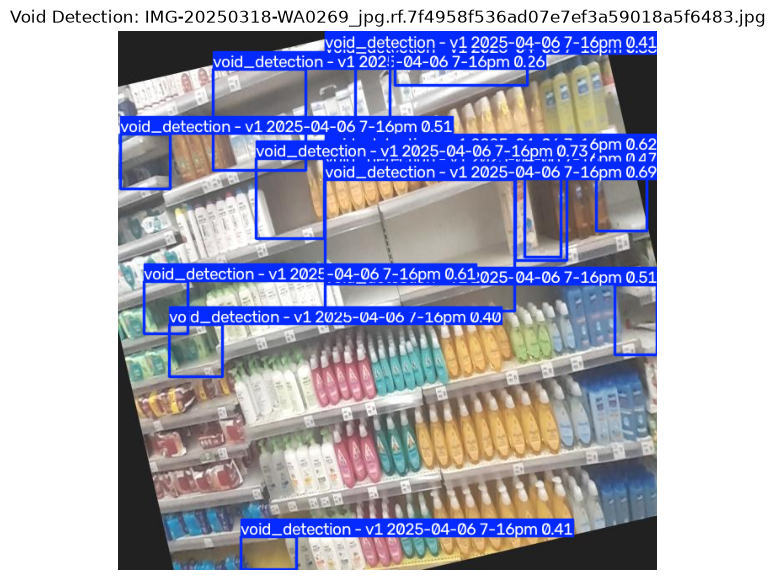

Predicted detections: 13


In [5]:
test_images = [
    p for p in (DATASET_DIR / "test" / "images").iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

if not test_images:
    raise FileNotFoundError("No test images found.")

image_path = random.choice(test_images)
prediction = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.25,
    device=DEVICE,
    save=True,
    verbose=False
)[0]

plt.figure(figsize=(10, 7))
plt.imshow(prediction.plot()[..., ::-1])
plt.title(f"Void Detection: {image_path.name}")
plt.axis("off")
plt.show()

print("Predicted detections:", len(prediction.boxes))

Compare ground truth vs predicted voids

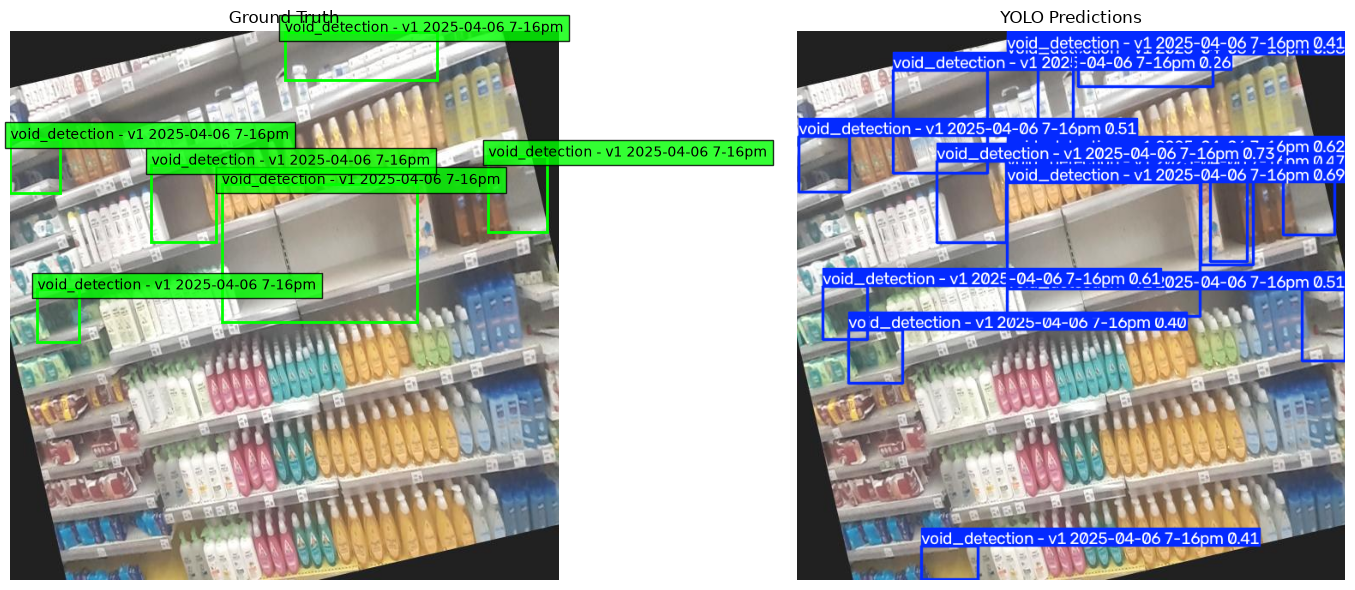

Ground-truth label: D:\Projects\cv_project\void_detection\data\test\labels\IMG-20250318-WA0269_jpg.rf.7f4958f536ad07e7ef3a59018a5f6483.txt
Predicted detections: 13


In [6]:
image = plt.imread(image_path)
label_path = DATASET_DIR / "test" / "labels" / f"{image_path.stem}.txt"
height, width = image.shape[:2]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(image)
axes[0].set_title("Ground Truth")

if label_path.is_file():
    for line in label_path.read_text().splitlines():
        values = line.split()
        if len(values) != 5:
            continue

        cls, xc, yc, bw, bh = map(float, values)
        x, y = (xc - bw / 2) * width, (yc - bh / 2) * height
        bw, bh = bw * width, bh * height

        axes[0].add_patch(Rectangle(
            (x, y), bw, bh, fill=False, edgecolor="lime", linewidth=2
        ))
        axes[0].text(x, y, model.names.get(int(cls), str(int(cls))),
                     color="black", bbox=dict(facecolor="lime", alpha=0.8))
else:
    axes[0].text(0.5, 0.5, "No ground-truth labels",
                 transform=axes[0].transAxes, ha="center")

axes[1].imshow(prediction.plot()[..., ::-1])
axes[1].set_title("YOLO Predictions")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Ground-truth label:", label_path)
print("Predicted detections:", len(prediction.boxes))

Visual Engine

Shelf area: 386,080 pixels
Detected voids: 4
Void area (union): 24,067 pixels
Void percentage: 6.23%
Non-void percentage: 93.77%
Estimated additional items: 7


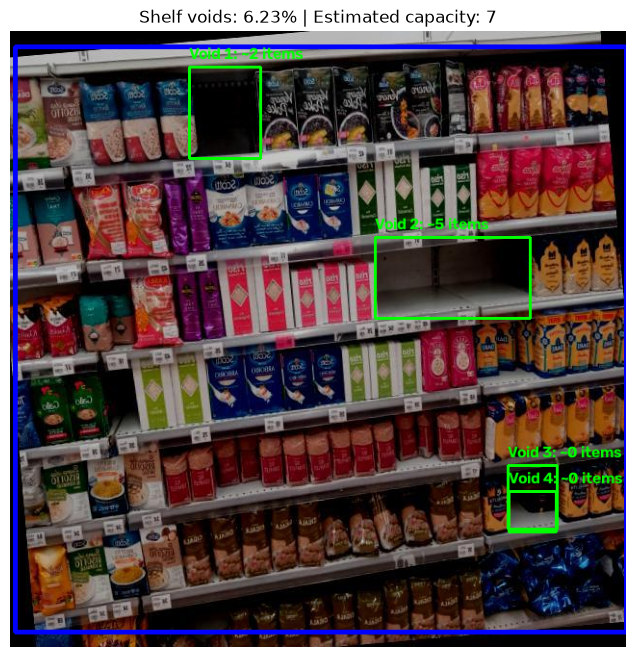

,Void,Width_px,Height_px,Area_px,Columns,Rows,Estimated_items
0,1,74,95,7030,2,1,2
1,2,161,84,13524,5,1,5
2,3,51,66,3366,1,0,0
3,4,49,42,2058,1,0,0


In [9]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import math

# Use the same image that was passed to YOLO
image_path = next((p for p in test_images if str(p) != str(image_path)), None)
if image_path is None:
    raise ValueError("No different image is available in test_images.")

image = cv2.imread(str(image_path))
image_path = test_images[np.random.randint(len(test_images))]
image = cv2.imread(str(image_path))
prediction = model.predict(source=str(image_path), verbose=False)[0]
if image is None:
    raise FileNotFoundError(f"Could not read image: {image_path}")

H, W = image.shape[:2]

# 1. SELECT THE SHELF ROI
# Select the complete shelf area, excluding surroundings.
# Press ENTER/SPACE to confirm; C to cancel.
shelf_roi = cv2.selectROI(
    "Select COMPLETE shelf area", image,
    showCrosshair=True, fromCenter=False
)
cv2.destroyAllWindows()

sx, sy, sw, sh = map(int, shelf_roi)
if sw <= 0 or sh <= 0:
    raise ValueError("Shelf selection cancelled or invalid.")

shelf_area = sw * sh

# 2. SELECT ONE REPRESENTATIVE PRODUCT
# Select the visible front face of one product.
# Choose a product with the same orientation as the void.
item_roi = cv2.selectROI(
    "Select ONE representative product", image,
    showCrosshair=True, fromCenter=False
)
cv2.destroyAllWindows()

ix, iy, iw, ih = map(int, item_roi)
if iw <= 0 or ih <= 0:
    raise ValueError("Product selection cancelled or invalid.")

# 3. GET YOLO VOID BOXES AND CLIP TO SHELF
void_boxes = []
for box in prediction.boxes:
    x1, y1, x2, y2 = map(
        int, box.xyxy[0].cpu().tolist()
    )

    # Intersection with the selected shelf rectangle
    x1 = max(x1, sx)
    y1 = max(y1, sy)
    x2 = min(x2, sx + sw)
    y2 = min(y2, sy + sh)

    if x2 > x1 and y2 > y1:
        void_boxes.append((x1, y1, x2, y2))

# 4. UNION AREA OF VOIDS (NO DOUBLE COUNTING)
void_mask = np.zeros((sh, sw), dtype=np.uint8)

for x1, y1, x2, y2 in void_boxes:
    cv2.rectangle(
        void_mask,
        (x1 - sx, y1 - sy),
        (x2 - sx - 1, y2 - sy - 1),
        1, thickness=-1
    )

void_pixels = int(void_mask.sum())
void_percentage = 100.0 * void_pixels / shelf_area
occupied_percentage = 100.0 - void_percentage

# 5. ESTIMATE CAPACITY FOR EACH VOID
# Assumes products are arranged in a simple grid.
results = []
total_estimated_items = 0

for index, (x1, y1, x2, y2) in enumerate(void_boxes, start=1):
    vw = x2 - x1
    vh = y2 - y1

    cols = vw // iw
    rows = vh // ih
    capacity = int(cols * rows)

    total_estimated_items += capacity
    results.append({
        "Void": index,
        "Width_px": vw,
        "Height_px": vh,
        "Area_px": vw * vh,
        "Columns": int(cols),
        "Rows": int(rows),
        "Estimated_items": capacity
    })

# 6. DISPLAY RESULTS
print(f"Shelf area: {shelf_area:,} pixels")
print(f"Detected voids: {len(void_boxes)}")
print(f"Void area (union): {void_pixels:,} pixels")
print(f"Void percentage: {void_percentage:.2f}%")
print(f"Non-void percentage: {occupied_percentage:.2f}%")
print(f"Estimated additional items: {total_estimated_items}")

# 7. VISUALIZE DETECTIONS AND CAPACITY
output = image.copy()

# Shelf boundary
cv2.rectangle(
    output, (sx, sy), (sx + sw, sy + sh),
    (255, 0, 0), 3
)

for result, (x1, y1, x2, y2) in zip(results, void_boxes):
    cv2.rectangle(output, (x1, y1), (x2, y2), (0, 255, 0), 2)
    label = f"Void {result['Void']}: ~{result['Estimated_items']} items"
    cv2.putText(
        output, label, (x1, max(20, y1 - 8)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 0), 2
    )

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title(f"Shelf voids: {void_percentage:.2f}% | "
          f"Estimated capacity: {total_estimated_items}")
plt.axis("off")
plt.show()

# Tabular breakdown
import pandas as pd
display(pd.DataFrame(results))


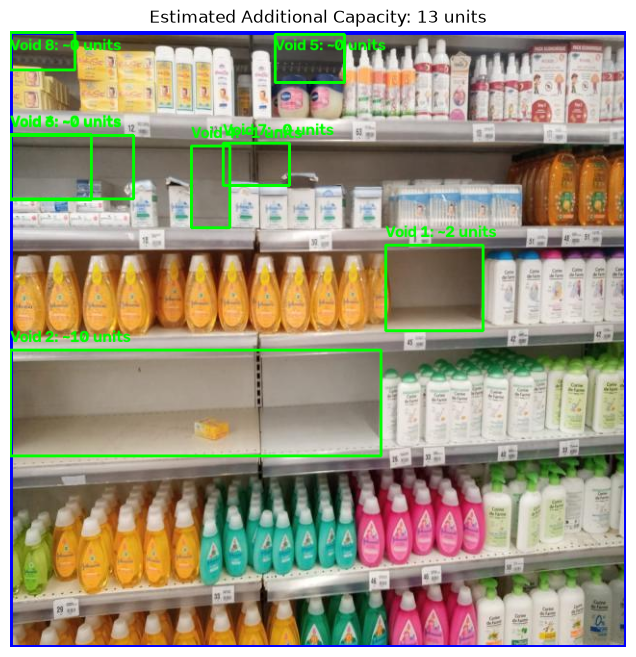

Image: IMG-20250318-WA0232_jpg.rf.da7fdf580071a738cefb00ca6f482d1f.jpg
Detected voids: 8
Selected product dimensions: 37 x 85 pixels
Estimated additional capacity: 13 units


,Void,Void Width (px),Void Height (px),Columns,Rows,Estimated Capacity (units)
0,1,101,89,2,1,2
1,2,385,110,10,1,10
2,3,128,66,3,0,0
3,4,40,85,1,1,1
4,5,72,50,1,0,0
5,6,84,68,2,0,0
6,7,69,44,1,0,0
7,8,67,39,1,0,0


Saved output: D:\Projects\cv_project\void_detection\data\valid\images\IMG-20250318-WA0232_jpg.rf.da7fdf580071a738cefb00ca6f482d1f_capacity_estimation.jpg


In [8]:

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tkinter import Tk, filedialog

# 1. SELECT ANY IMAGE FROM YOUR COMPUTER
root = Tk()
root.withdraw()
root.attributes("-topmost", True)

image_path = filedialog.askopenfilename(
    title="Select Warehouse Shelf Image",
    filetypes=[("Images", "*.jpg *.jpeg *.png *.bmp *.webp *.tif *.tiff")]
)
root.destroy()

if not image_path:
    print("No image selected.")
else:
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError("Could not load the selected image.")

    H, W = image.shape[:2]

    # 2. RUN YOUR TRAINED VOID DETECTION MODEL
    prediction = model.predict(
        source=image,
        imgsz=640,
        conf=0.25,
        device=DEVICE,
        verbose=False
    )[0]

    # 3. SELECT THE COMPLETE SHELF
    shelf_roi = cv2.selectROI(
        "Select COMPLETE shelf area",
        image, showCrosshair=True, fromCenter=False
    )
    cv2.destroyAllWindows()

    sx, sy, sw, sh = map(int, shelf_roi)

    if sw <= 0 or sh <= 0:
        raise ValueError("Shelf selection cancelled.")

    # 4. SELECT ONE PRODUCT OF THE TYPE YOU WANT TO STORE
    item_roi = cv2.selectROI(
        "Select ONE representative product",
        image, showCrosshair=True, fromCenter=False
    )
    cv2.destroyAllWindows()

    ix, iy, iw, ih = map(int, item_roi)

    if iw <= 0 or ih <= 0:
        raise ValueError("Product selection cancelled.")

    # 5. GET DETECTED VOIDS INSIDE THE SELECTED SHELF
    void_boxes = []

    for box in prediction.boxes:
        x1, y1, x2, y2 = map(
            int, box.xyxy[0].cpu().tolist()
        )

        x1, y1 = max(x1, sx), max(y1, sy)
        x2, y2 = min(x2, sx + sw), min(y2, sy + sh)

        if x2 > x1 and y2 > y1:
            void_boxes.append((x1, y1, x2, y2))

    # 6. ESTIMATE PRODUCT CAPACITY
    results = []
    total_capacity = 0
    output = image.copy()

    cv2.rectangle(
        output, (sx, sy), (sx + sw, sy + sh),
        (255, 0, 0), 3
    )

    for index, (x1, y1, x2, y2) in enumerate(
        void_boxes, start=1
    ):
        vw, vh = x2 - x1, y2 - y1

        # Simple grid packing; assumes matching orientation
        columns = vw // iw
        rows = vh // ih
        capacity = int(columns * rows)

        total_capacity += capacity

        results.append({
            "Void": index,
            "Void Width (px)": vw,
            "Void Height (px)": vh,
            "Columns": int(columns),
            "Rows": int(rows),
            "Estimated Capacity (units)": capacity
        })

        cv2.rectangle(
            output, (x1, y1), (x2, y2), (0, 255, 0), 2
        )

        label = f"Void {index}: ~{capacity} units"
        cv2.putText(
            output, label, (x1, max(20, y1 - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.55,
            (0, 255, 0), 2
        )

    # 7. DISPLAY OUTPUT
    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.title(f"Estimated Additional Capacity: {total_capacity} units")
    plt.axis("off")
    plt.show()

    print("Image:", Path(image_path).name)
    print("Detected voids:", len(void_boxes))
    print("Selected product dimensions:", f"{iw} x {ih} pixels")
    print("Estimated additional capacity:", total_capacity, "units")

    if results:
        display(pd.DataFrame(results))
    else:
        print("No voids detected inside the selected shelf.")

    # 8. SAVE OUTPUT
    output_path = str(
        Path(image_path).with_name(
            Path(image_path).stem + "_capacity_estimation.jpg"
        )
    )
    cv2.imwrite(output_path, output)
    print("Saved output:", output_path)
